# DEP Experiment-3

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.subplots as sp
import plotly.graph_objects as go
import pandas as pd
import numpy as np

In [34]:
df = pd.read_csv("Datasets/Ex3_Viz_Sttudent_performance.csv")
df = df.sort_values(by='Study_Hours_Per_Week')

### SET 1 : Common Graphs (Same Plot, Three Libraries)

1. Line Plot – Study Hours vs Marks

Seaborn 

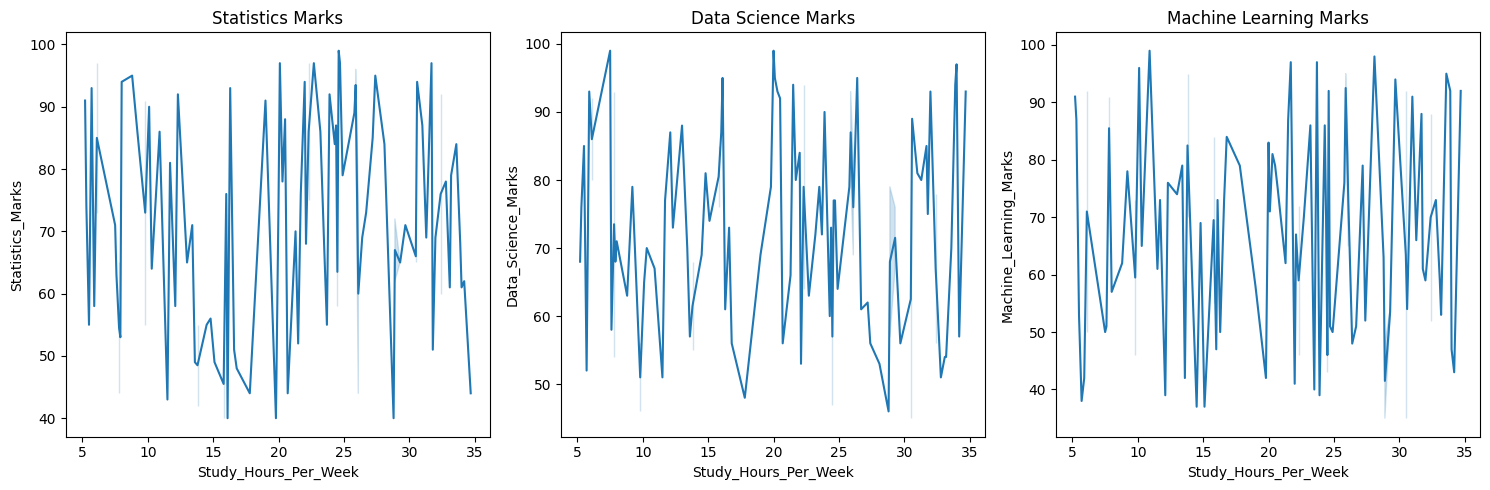

In [35]:
fig, axes = plt.subplots(1,3, figsize=(15,5))
sns.lineplot(x="Study_Hours_Per_Week", y="Statistics_Marks", data=df, ax=axes[0])
axes[0].set_title("Statistics Marks")

sns.lineplot(x="Study_Hours_Per_Week", y="Data_Science_Marks", data=df, ax=axes[1])
axes[1].set_title("Data Science Marks")

sns.lineplot(x="Study_Hours_Per_Week", y="Machine_Learning_Marks", data=df, ax=axes[2])
axes[2].set_title("Machine Learning Marks")

plt.tight_layout()
plt.show()

Matplotlib

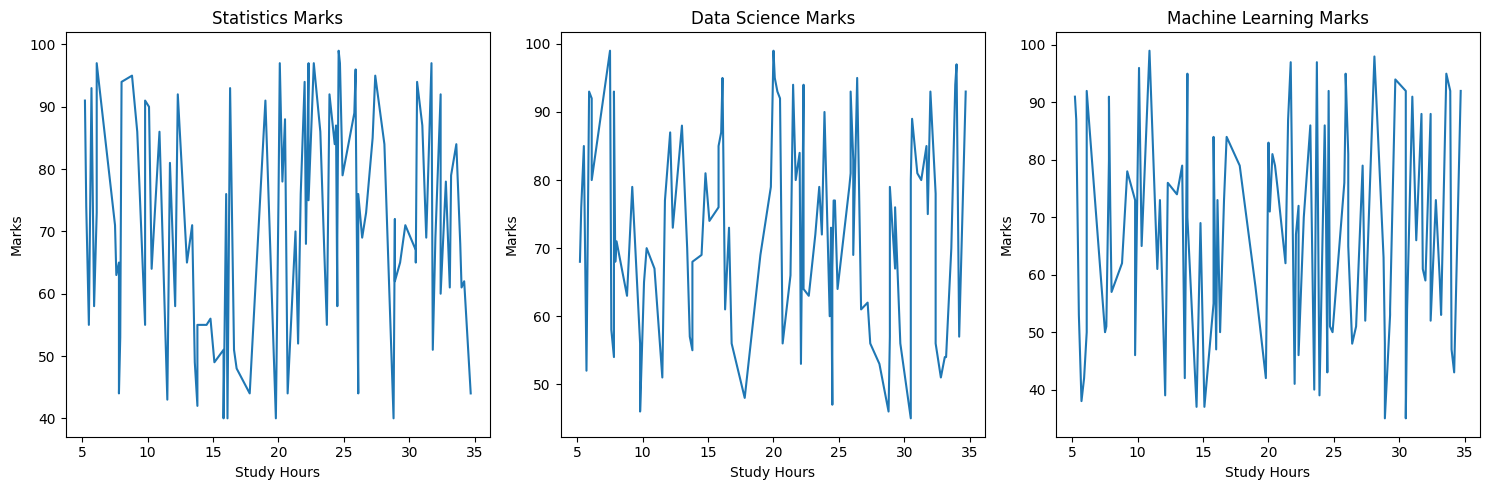

In [36]:
plt.figure(figsize=(15,5))

# Statistics
plt.subplot(1,3,1)
plt.plot(df['Study_Hours_Per_Week'], df['Statistics_Marks'])
plt.title("Statistics Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")

# Data Science
plt.subplot(1,3,2)
plt.plot(df['Study_Hours_Per_Week'], df['Data_Science_Marks'])
plt.title("Data Science Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")

# ML
plt.subplot(1,3,3)
plt.plot(df['Study_Hours_Per_Week'], df['Machine_Learning_Marks'])
plt.title("Machine Learning Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")

plt.tight_layout()
plt.show()

Plotly

In [37]:
fig = sp.make_subplots(rows=1, cols=3,
                       subplot_titles=("Statistics Marks", "Data Science Marks", "Machine Learning Marks"))
# Statistics
fig.add_trace(
    go.Scatter(x=df["Study_Hours_Per_Week"], y=df["Statistics_Marks"],
               mode="lines", name="Statistics"),
    row=1, col=1
)
# Data Science
fig.add_trace(
    go.Scatter(x=df["Study_Hours_Per_Week"], y=df["Data_Science_Marks"], mode="lines", name="Data Science"),
    row=1, col=2
)
# ML
fig.add_trace(
    go.Scatter(x=df["Study_Hours_Per_Week"], y=df["Machine_Learning_Marks"], mode="lines", name="Machine Learning"),
    row=1, col=3
)
fig.update_layout(title="Study Hours vs Marks", width=950, height=400)
fig.show()

### SET 2: Seaborn-Specific Statistical Visualizations (3 Graphs)

1. Box Plot – Marks distribution by Department

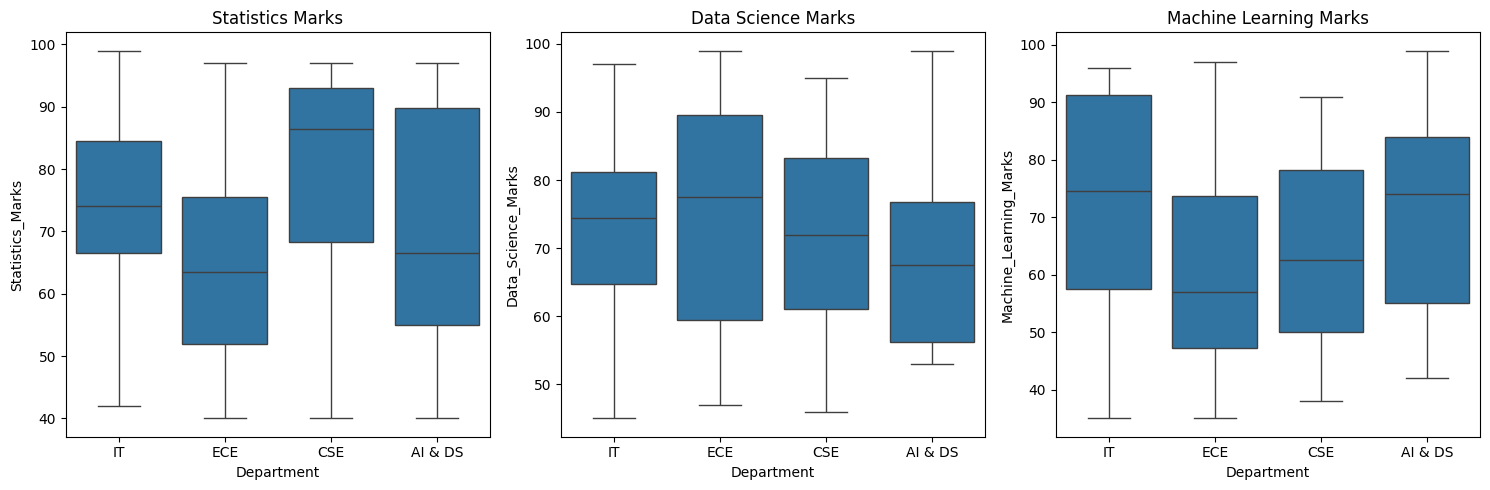

In [38]:
fig, axes = plt.subplots(1,3, figsize=(15,5))
sns.boxplot(x="Department", y="Statistics_Marks", data=df, ax=axes[0])
axes[0].set_title("Statistics Marks")

sns.boxplot(x="Department", y="Data_Science_Marks", data=df, ax=axes[1])
axes[1].set_title("Data Science Marks")

sns.boxplot(x="Department", y="Machine_Learning_Marks", data=df, ax=axes[2])
axes[2].set_title("Machine Learning Marks")

plt.tight_layout()
plt.show()

2. Violin Plot – Marks vs Semester

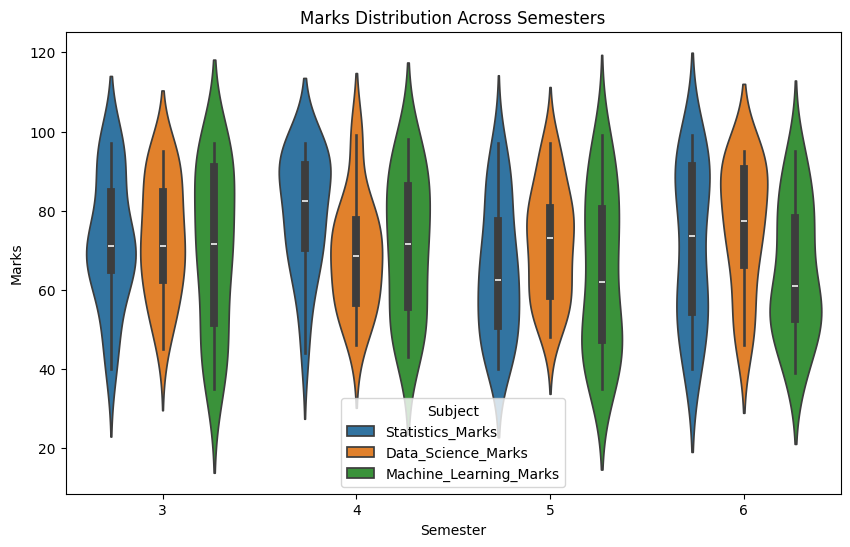

In [39]:
# Convert marks columns into long format
df_melt = df.melt(id_vars="Semester",
                  value_vars=["Statistics_Marks", "Data_Science_Marks", "Machine_Learning_Marks"], 
                  var_name="Subject",
                  value_name="Marks")

plt.figure(figsize=(10,6))

sns.violinplot(x="Semester", y="Marks", hue="Subject", data=df_melt)
plt.title("Marks Distribution Across Semesters")
plt.show()

3. Heatmap – Correlation between numeric features

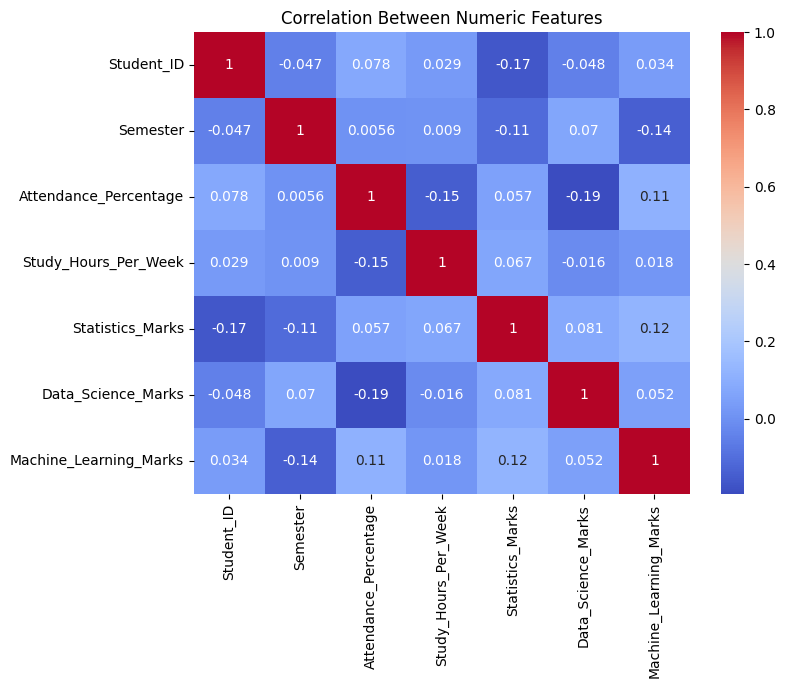

In [40]:
# Select numeric columns
numeric_df = df.select_dtypes(include=['number'])
# Compute correlation matrix
corr_matrix = numeric_df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Between Numeric Features")
plt.show()

### SET 3: Matplotlib-Specific Visualizations (3 Graphs)

1. Histogram - Marks Distributrion

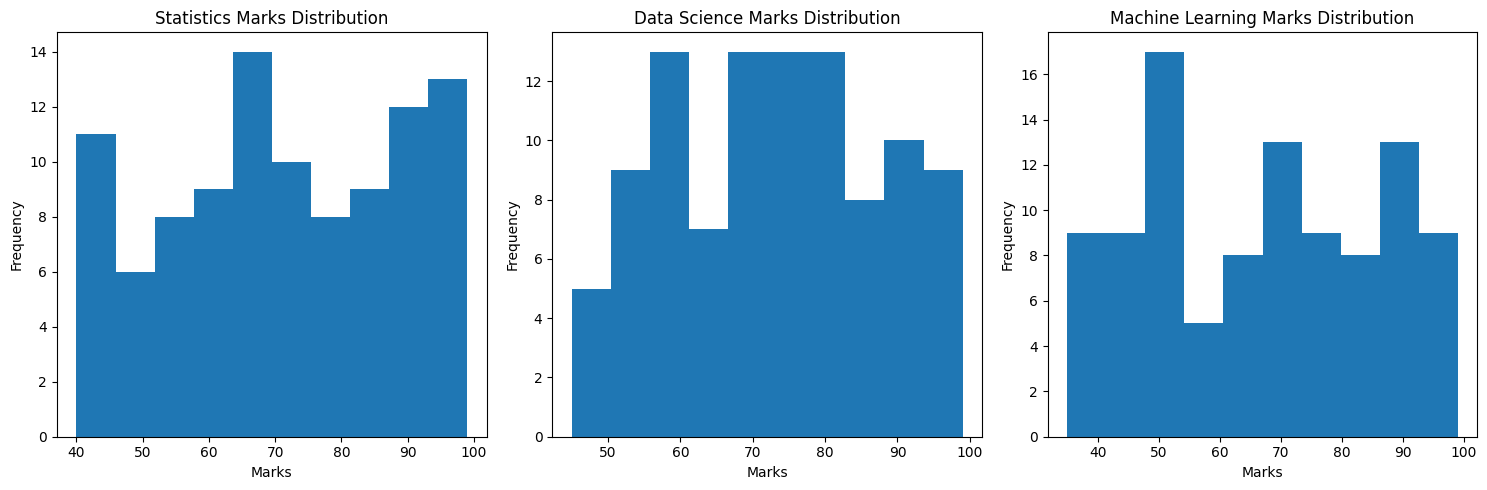

In [41]:
plt.figure(figsize=(15,5))

# Statistics Marks
plt.subplot(1,3,1)
plt.hist(df["Statistics_Marks"], bins=10)
plt.title("Statistics Marks Distribution")
plt.xlabel("Marks")
plt.ylabel("Frequency")
# Data Science Marks
plt.subplot(1,3,2)
plt.hist(df["Data_Science_Marks"], bins=10)
plt.title("Data Science Marks Distribution")
plt.xlabel("Marks")
plt.ylabel("Frequency")
# Machine Learning Marks
plt.subplot(1,3,3)
plt.hist(df["Machine_Learning_Marks"], bins=10)
plt.title("Machine Learning Marks Distribution")
plt.xlabel("Marks")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

2. Error Bar Plot – Mean marks with standard deviation

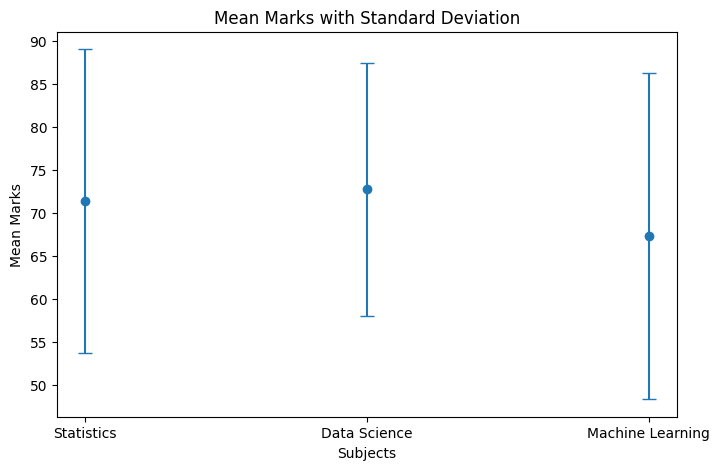

In [42]:
# Calculate mean
means = [
    df["Statistics_Marks"].mean(),
    df["Data_Science_Marks"].mean(),
    df["Machine_Learning_Marks"].mean()
]
# Calculate standard deviation
stds = [
    df["Statistics_Marks"].std(),
    df["Data_Science_Marks"].std(),
    df["Machine_Learning_Marks"].std()
]
subjects = ["Statistics", "Data Science", "Machine Learning"]

plt.figure(figsize=(8,5))
plt.errorbar(subjects, means, yerr=stds, fmt='o', capsize=5)
plt.title("Mean Marks with Standard Deviation")
plt.xlabel("Subjects")
plt.ylabel("Mean Marks")
plt.show()

3. Pie Chart

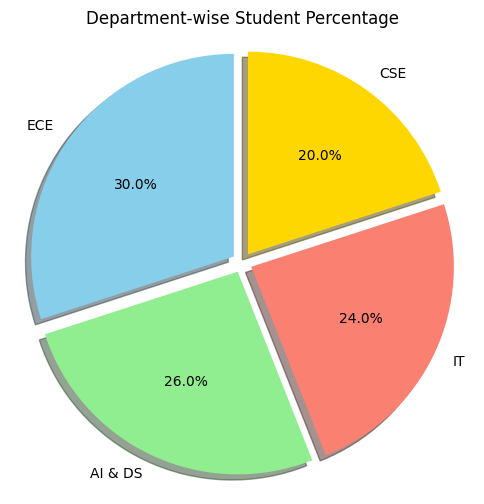

In [43]:
dept_counts = df["Department"].value_counts() # Count students in each department
labels = dept_counts.index
sizes = dept_counts.values
colors = ["skyblue", "lightgreen", "salmon", "gold"]
explode = [0.05] * len(labels) # slight separation for all slices

plt.figure(figsize=(6,6))
plt.pie(sizes, labels=labels, autopct="%1.1f%%", colors=colors, explode=explode, startangle=90, shadow=True)
plt.title("Department-wise Student Percentage")
plt.axis("equal")
plt.show()

### SET 4: Plotly Express-Specific Interactive Visualizations

1. Interactive Scatter Plot - Hover details enabled

In [44]:
df_melt = df.melt(
    id_vars=["Study_Hours_Per_Week", "Department", "Semester"],
    value_vars=["Statistics_Marks", "Data_Science_Marks", "Machine_Learning_Marks"],
    var_name="Subject",
    value_name="Marks"
) # Convert marks columns to long format

fig = px.scatter(
    df_melt,
    x="Study_Hours_Per_Week",
    y="Marks",
    color="Subject",
    hover_data=["Department", "Semester", "Marks"],
    title="Study Hours vs Marks (Interactive Scatter Plot)"
)

fig.show()

2. Bubble Chart – Marks vs Study Hours (size = Attendance)

In [45]:
# Convert marks columns to long format
df_melt = df.melt(
    id_vars=["Study_Hours_Per_Week", "Attendance_Percentage", "Department"],
    value_vars=["Statistics_Marks", "Data_Science_Marks", "Machine_Learning_Marks"],
    var_name="Subject",
    value_name="Marks"
)

fig = px.scatter(
    df_melt,
    x="Study_Hours_Per_Week",
    y="Marks",
    size="Attendance_Percentage",       # Bubble size
    color="Subject",         # Different color per subject
    hover_data=["Department", "Attendance_Percentage"],
    title="Bubble Chart: Study Hours vs Marks (Bubble Size = Attendance)"
)

fig.show()

3. Animated Line Plot – Average marks over semesters

In [46]:
df_melt = df.melt(
    id_vars=["Semester"],
    value_vars=["Statistics_Marks", "Data_Science_Marks", "Machine_Learning_Marks"],
    var_name="Subject", value_name="Marks"
) # Melt marks columns to long format

# Average marks per semester per subject
avg_marks = df_melt.groupby(["Semester", "Subject"])["Marks"].mean().reset_index()

# Build cumulative frames: frame N shows semesters 1 … N so the line grows
semesters = sorted(avg_marks["Semester"].unique())
frames_data = []
for sem in semesters:
    subset = avg_marks[avg_marks["Semester"] <= sem].copy()
    subset["frame"] = sem
    frames_data.append(subset)

df_animated = pd.concat(frames_data, ignore_index=True)

fig = px.line(
    df_animated, x="Semester", y="Marks", color="Subject", animation_frame="frame",
    markers=True,
    title="Animated Line Plot: Average Marks Over Semesters",
    range_x=[semesters[0] - 0.3, semesters[-1] + 0.3],
    range_y=[avg_marks["Marks"].min() - 5, avg_marks["Marks"].max() + 5],
    labels={"Marks": "Average Marks", "Semester": "Semester"}
)

fig.update_layout(
    xaxis=dict(tickmode="linear", dtick=1),
    legend_title="Subject"
)

fig.show()

### SET 5: Unique Signature Graphs 

1. Seaborn: Pair Plot – Relationships between multiple features

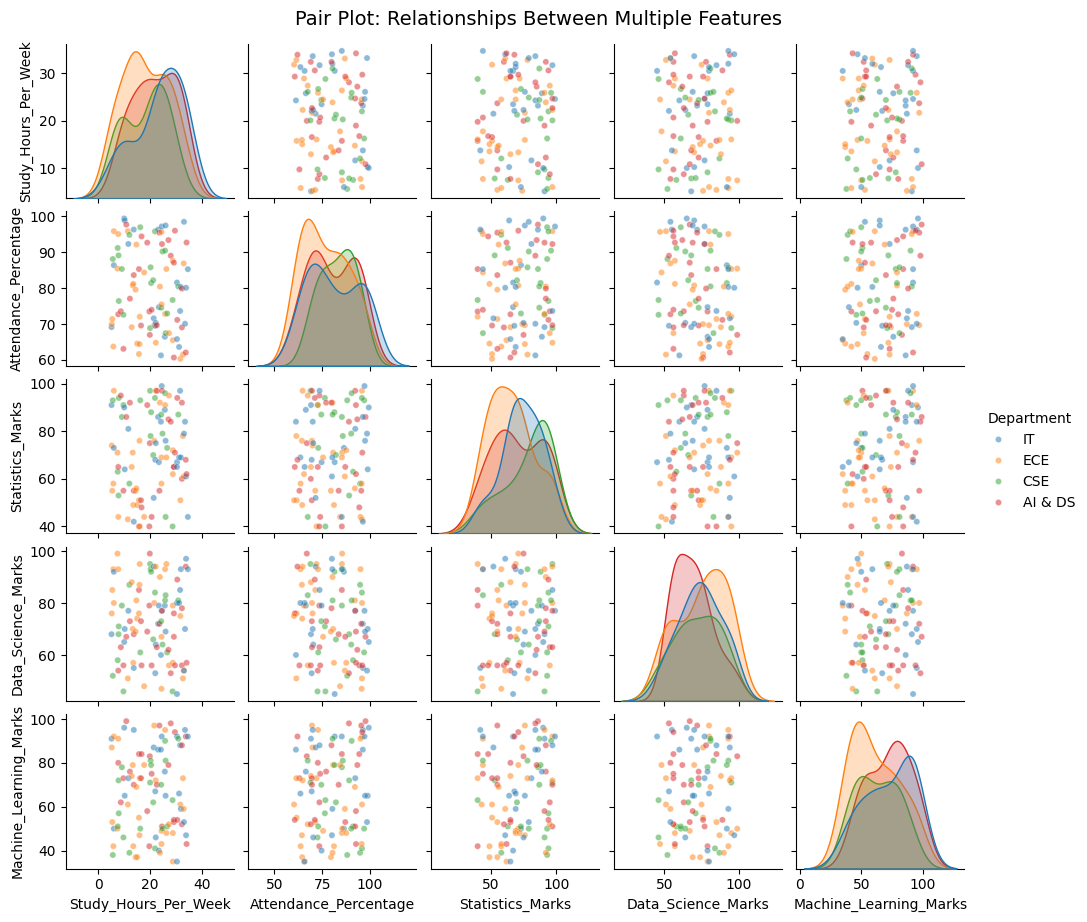

In [58]:
# Select relevant numeric features for the pair plot
features = df[[
    "Study_Hours_Per_Week",
    "Attendance_Percentage",
    "Statistics_Marks",
    "Data_Science_Marks",
    "Machine_Learning_Marks",
    "Department"
]]

pair_plot = sns.pairplot(
    features,
    hue="Department",
    diag_kind="kde",
    plot_kws={"alpha": 0.5, "s": 20},
    corner=False,
    height=1.8,
    aspect=1.1
)

pair_plot.figure.suptitle("Pair Plot: Relationships Between Multiple Features", y=1.02, fontsize=14)
plt.show()


2. Matplotlib: Polar Plot – Any meaningful circular data

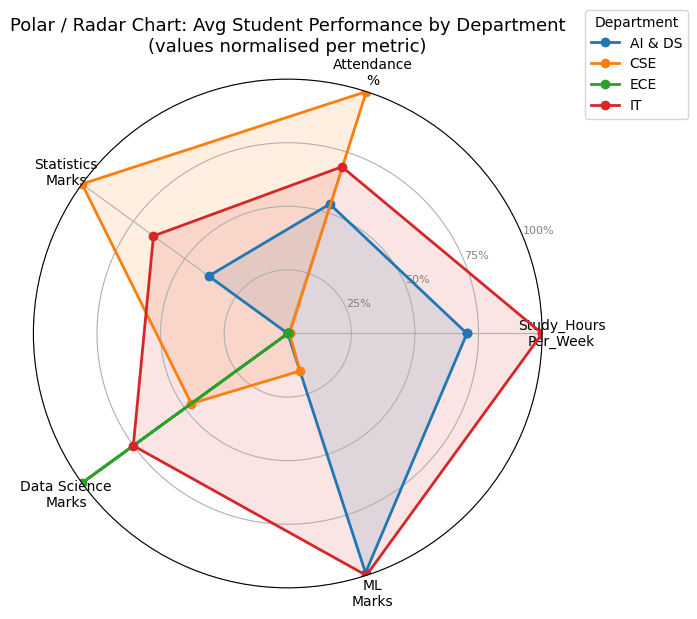

In [57]:
categories = ["Study_Hours\nPer_Week", "Attendance\n%", "Statistics\nMarks",
              "Data Science\nMarks", "ML\nMarks"]
cols = ["Study_Hours_Per_Week", "Attendance_Percentage",
        "Statistics_Marks", "Data_Science_Marks", "Machine_Learning_Marks"]

# Average per department, then normalise each metric to [0, 1]
dept_avg = df.groupby("Department")[cols].mean()
dept_norm = (dept_avg - dept_avg.min()) / (dept_avg.max() - dept_avg.min())
departments = dept_norm.index.tolist()
N = len(categories)

# Evenly space angles and closing the loop
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
cmap = plt.get_cmap("tab10")

for i, dept in enumerate(departments):
    values = dept_norm.loc[dept].tolist()
    values += values[:1] # Closing the polygon
    ax.plot(angles, values, "o-", linewidth=2, label=dept, color=cmap(i))
    ax.fill(angles, values, alpha=0.12, color=cmap(i))

# Axis labels
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["25%", "50%", "75%", "100%"], fontsize=8, color="grey")
ax.set_ylim(0, 1)
ax.set_title("Polar / Radar Chart: Avg Student Performance by Department\n"
             "(values normalised per metric)", fontsize=13, pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.15), title="Department")
plt.tight_layout()
plt.show()

3. Plotly Express: Treemap – Hierarchical or categorical data

In [51]:
# Aggregate: count students and compute average marks per Department → Semester
df_tree = df.groupby(["Department", "Semester"]).agg(
    Student_Count=("Student_ID", "count"),
    Avg_Marks=("Statistics_Marks", "mean")
).reset_index()

df_tree["Semester_Label"] = "Sem " + df_tree["Semester"].astype(str)

fig = px.treemap(
    df_tree, path=[px.Constant("All"), "Department", "Semester_Label"],
    values="Student_Count",
    color="Avg_Marks",
    color_continuous_scale="RdYlGn",
    color_continuous_midpoint=df_tree["Avg_Marks"].mean(),
    title="Treemap: Student Distribution by Department & Semester<br>"
          "<sup>Size = No. of Students | Color = Avg Statistics Marks</sup>",
    hover_data={"Student_Count": True, "Avg_Marks": ":.1f"}
)

fig.update_traces(root_color="lightgrey", textinfo="label+value")
fig.update_layout(margin=dict(t=60, l=10, r=10, b=10), coloraxis_colorbar_title="Avg Marks")

fig.show()
